In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# بارگذاری داده
df = pd.read_csv("EURUSD_15m_BID_01.01.2010-31.12.2016.csv")

# تبدیل زمان
df['Time'] = pd.to_datetime(df['Time'])
df = df.sort_values('Time').reset_index(drop=True)

# تبدیل ستون‌ها
for c in ['Open', 'High', 'Low', 'Close']:
    df[c] = df[c].astype(float)

# حذف کندل‌های مرده (Volume = 0)
df = df[df['Volume'] > 0].reset_index(drop=True)

print("Rows after cleaning:", len(df))
df.head()


Rows after cleaning: 174734


,Time,Open,High,Low,Close,Volume
0,2010-01-01 00:00:00,1.43283,1.43293,1.43224,1.43293,608600007.1
1,2010-01-01 00:15:00,1.43285,1.43295,1.43229,1.43275,535600003.2
2,2010-01-01 00:30:00,1.43280,1.43303,1.43239,1.43281,436299999.2
3,2010-01-01 00:45:00,1.43285,1.43294,1.43229,1.43276,614299997.3
4,2010-01-01 01:00:00,1.43287,1.43292,1.43206,1.43282,705300008.8


In [9]:
ATR_PERIOD = 14

high = df['High']
low = df['Low']
close = df['Close']
prev_close = close.shift(1)

# محاسبه True Range
tr = pd.concat([
    high - low,
    (high - prev_close).abs(),
    (low - prev_close).abs()
], axis=1).max(axis=1)

# ATR
df['ATR'] = tr.rolling(ATR_PERIOD).mean()


In [10]:
L, R = 3, 3
p1 = np.zeros(len(df), dtype=bool)

for i in range(L, len(df) - R):
    if df['High'].iloc[i] == df['High'].iloc[i-L:i+R+1].max():
        p1[i] = True

df['P1'] = p1


In [12]:
LOOKAHEAD = 48
MAX_ALPHA = 5.0

alpha_star = np.full(len(df), np.nan)

for i in np.where(df['P1'])[0]:
    if i + LOOKAHEAD >= len(df):
        continue
    if np.isnan(df['ATR'].iloc[i]):
        continue

    future_low = df['Low'].iloc[i+1:i+LOOKAHEAD+1].min()
    raw_alpha = (df['High'].iloc[i] - future_low) / df['ATR'].iloc[i]
    alpha_star[i] = min(raw_alpha, MAX_ALPHA)

df['alpha_star'] = alpha_star


In [13]:
ALPHA_TRADE = 0.7
SL_ATR = 1.0
TP_ATR = 1.0
HORIZON = 48

results = []        # نتیجه هر معامله
equity = [0]        # اکوئیتی R-based
trade_dates = []    # تاریخ معاملات

for i in np.where(
    (df['P1']) &
    (df['alpha_star'] >= 1.0) &
    (df['Exhaustion'] >= 0.6)
)[0]:

    if i + HORIZON >= len(df):
        continue

    atr = df['ATR'].iloc[i]
    if np.isnan(atr):
        continue

    P1 = df['High'].iloc[i]

    entry = P1 - ALPHA_TRADE * atr
    stop = entry + SL_ATR * atr
    target = entry - TP_ATR * atr

    trade_open = False

    for j in range(i + 1, i + HORIZON):
        hi = df['High'].iloc[j]
        lo = df['Low'].iloc[j]

        if not trade_open:
            if lo <= entry <= hi:
                trade_open = True
        else:
            if hi >= stop:
                results.append(-1)
                equity.append(equity[-1] - 1)
                trade_dates.append(df['Time'].iloc[j])
                break

            if lo <= target:
                results.append(1)
                equity.append(equity[-1] + 1)
                trade_dates.append(df['Time'].iloc[j])
                break


In [14]:
trades = pd.DataFrame({
    'date': trade_dates,
    'result': results
})

trades['year'] = trades['date'].dt.year

# آمار سالانه
yearly = trades.groupby('year').agg(
    total_trades=('result', 'count'),
    wins=('result', lambda x: np.sum(x == 1)),
    losses=('result', lambda x: np.sum(x == -1))
)

yearly['win_rate'] = yearly['wins'] / yearly['total_trades']

print(yearly[['total_trades', 'win_rate']].round(3))


      total_trades  win_rate
year                        
2010           491     0.774
2011           581     0.737
2012           662     0.743
2013           709     0.757
2014           702     0.719
2015           689     0.736
2016           701     0.746


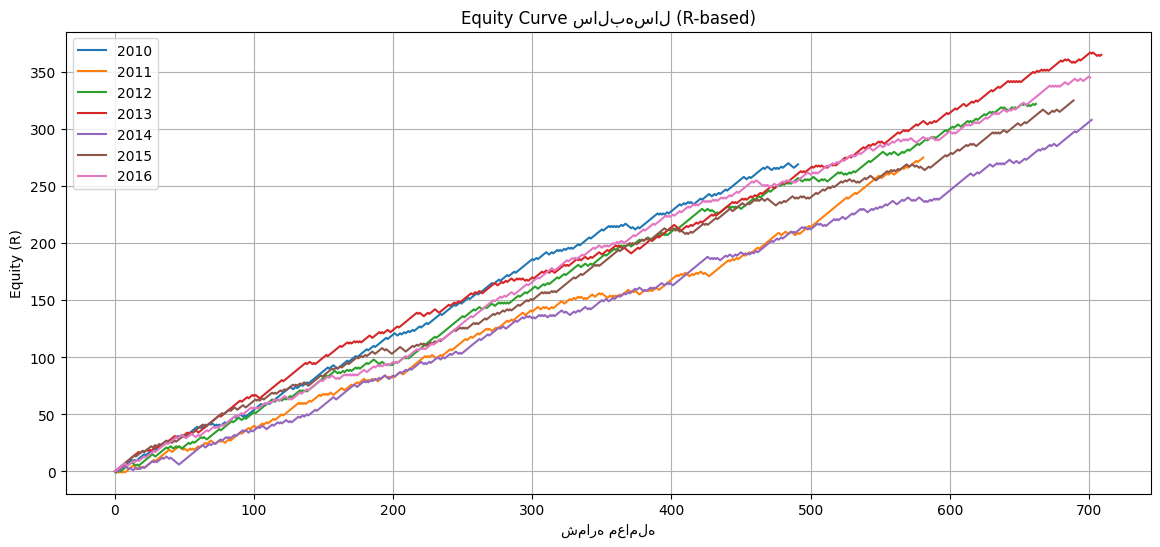

In [15]:
plt.figure(figsize=(14,6))

for y in sorted(trades['year'].unique()):
    r = trades[trades['year'] == y]['result'].values
    eq = np.cumsum(r)
    eq = np.insert(eq, 0, 0)

    plt.plot(eq, label=str(y))

plt.title("Equity Curve سال‌به‌سال (R-based)")
plt.xlabel("شماره معامله")
plt.ylabel("Equity (R)")
plt.legend()
plt.grid(True)
plt.show()
